# Cancer Prediction

Binary classification: predict whether a breast tumour is benign or malignant from 30 measurements of cell nuclei. Built during the Acmegrade Machine Learning Internship (Feb–Apr 2024). Research/learning project on a public dataset — **not a medical device and not for clinical use**.

In [16]:
%matplotlib inline
import numpy as np 
import pandas as pd
import seaborn as s
from sklearn import model_selection
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from xgboost import XGBClassifier
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

## Data — Wisconsin Breast Cancer Diagnostic dataset

569 samples, 30 numeric features, target `diagnosis`: 357 benign (B → 0) and 212 malignant (M → 1). The `id` column is dropped from the features (`iloc[:, 2:33]`). No missing values.

In [17]:
cp = pd.read_csv('data.csv')
cp

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [18]:
display (cp['diagnosis'].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64

In [19]:
print (cp.dtypes)

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [20]:
le = LabelEncoder()
cp['diagnosis'] = le.fit_transform(cp['diagnosis'])
print('Classes:', list(le.classes_))


Classes: ['B', 'M']


In [21]:
print(cp.dtypes)


id                           int64
diagnosis                    int32
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [22]:
display(cp)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [23]:
x= cp.iloc[:,2:33]
y = cp['diagnosis']
display(x)
display(y)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: diagnosis, Length: 569, dtype: int32

In [24]:
display (x.isnull().sum())

radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

## Exploratory analysis

Correlation heatmap of the 30 features, then distribution plots of each feature split by diagnosis (benign vs malignant).

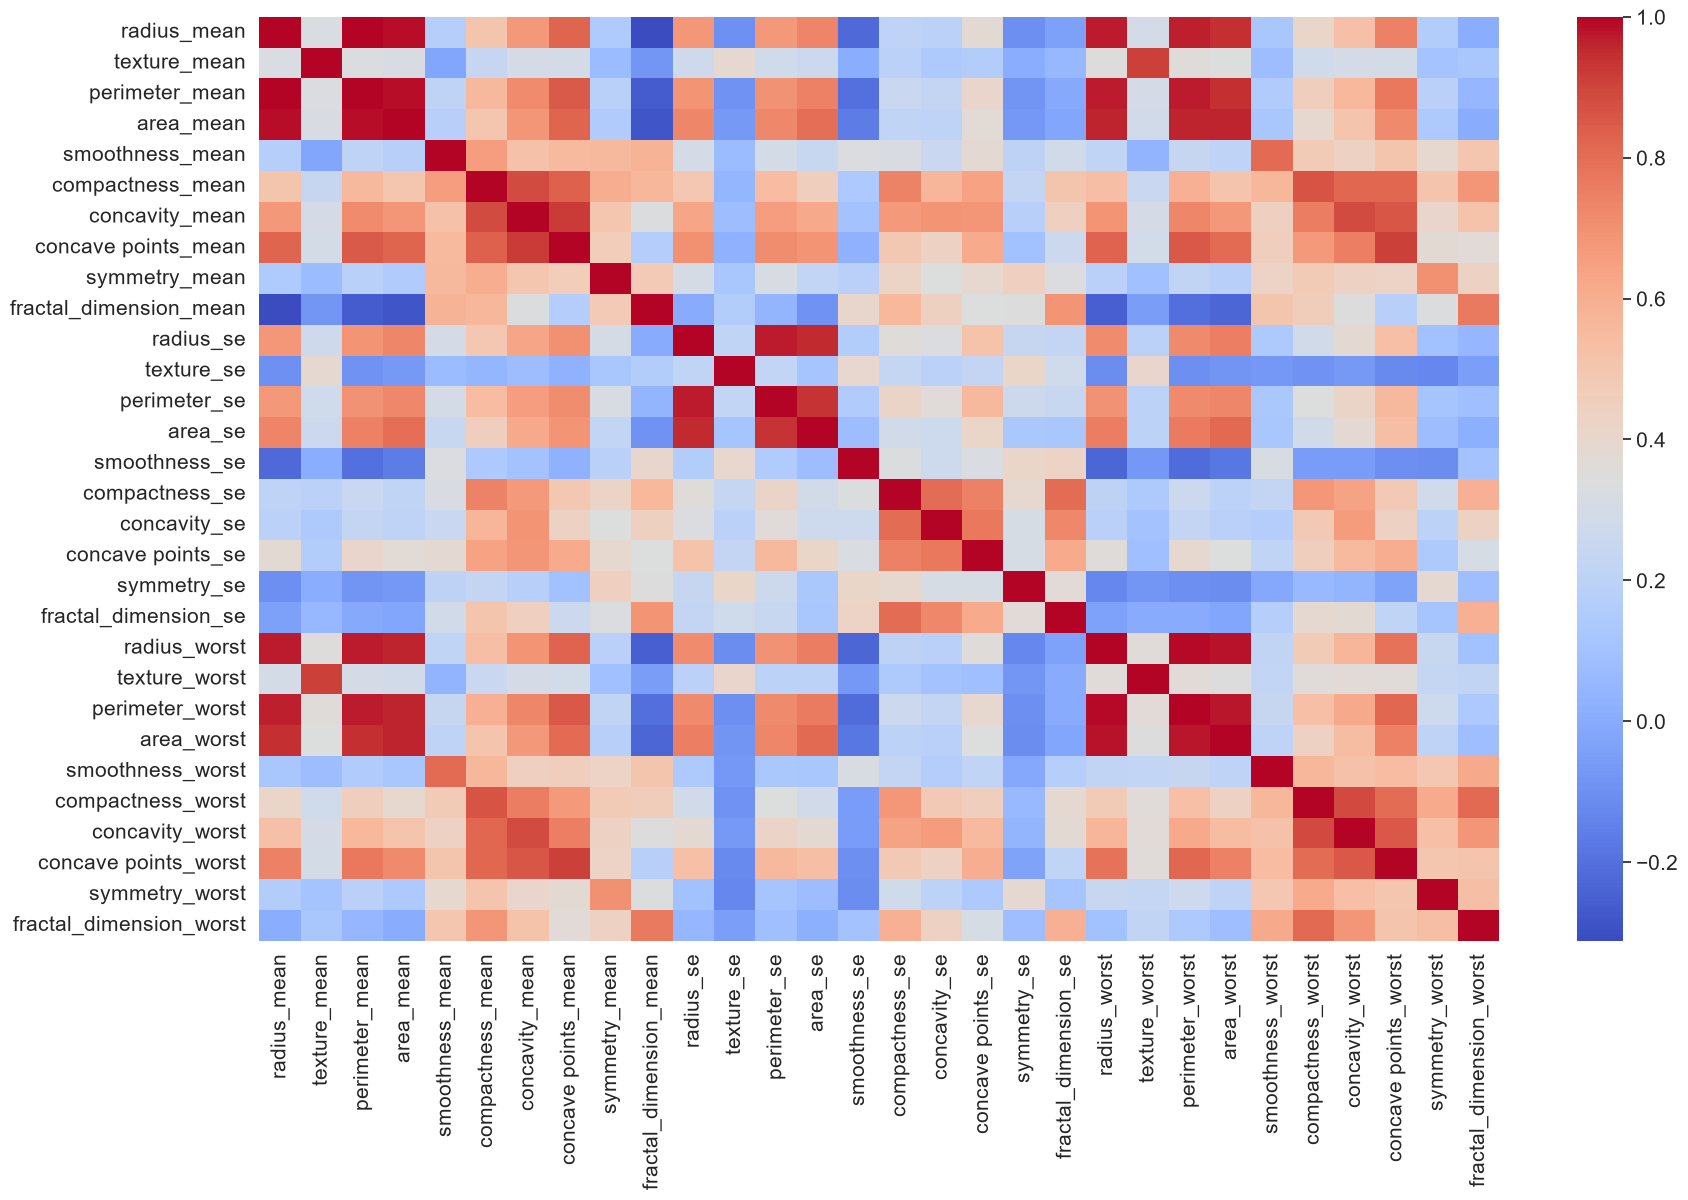

In [25]:
plt.rcParams['figure.figsize']=(20,12)
s.set(font_scale=1.4)
s.heatmap (x.corr(),cmap = 'coolwarm')
plt.show()

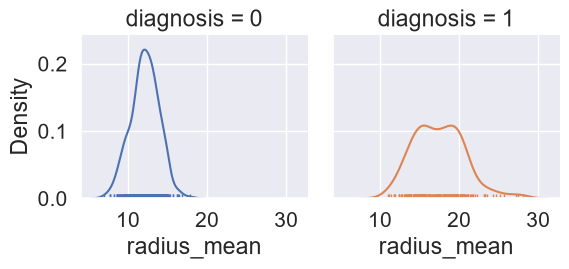

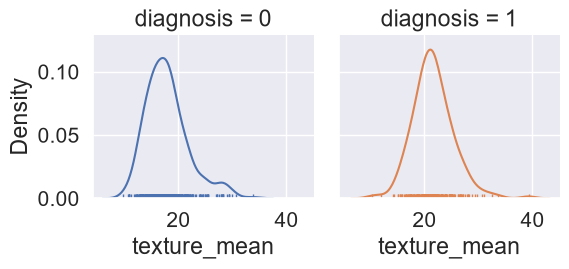

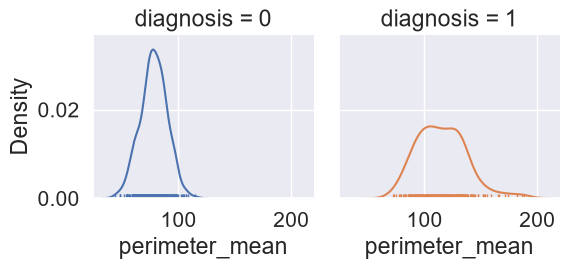

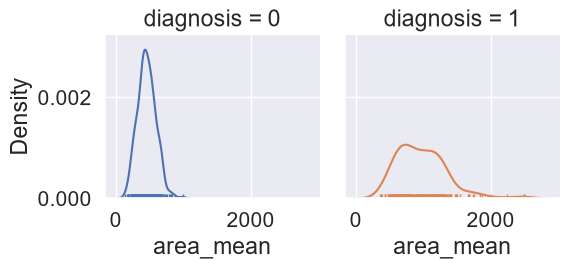

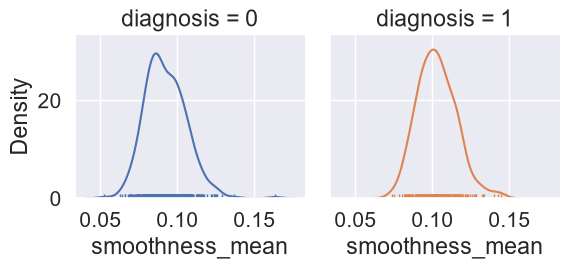

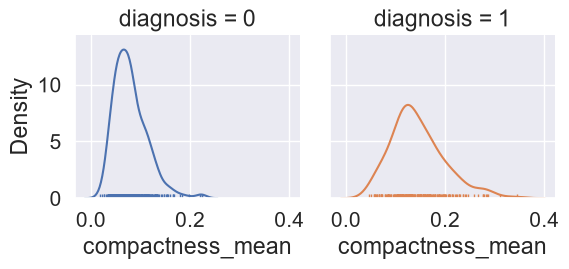

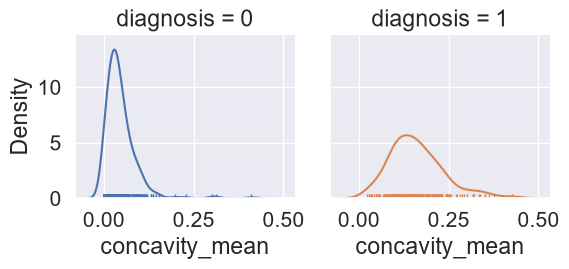

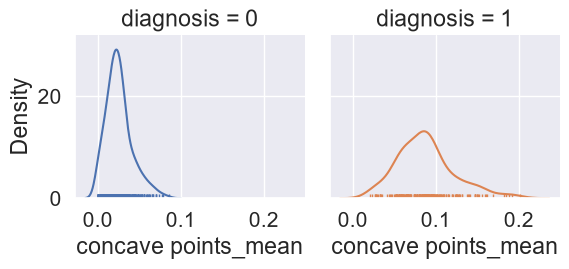

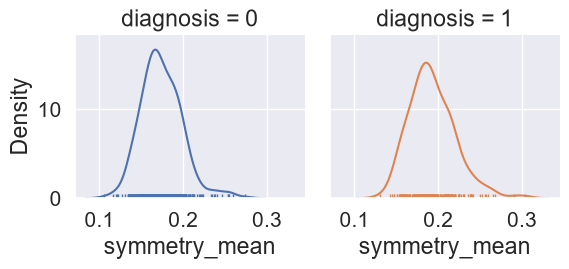

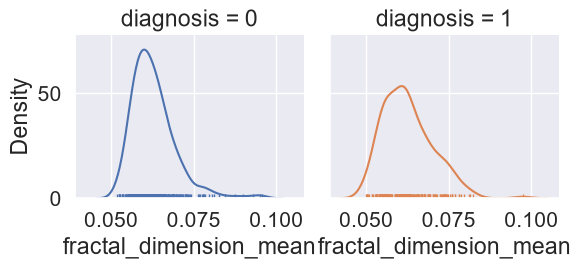

In [26]:
g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "radius_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'texture_mean', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'perimeter_mean', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "area_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "smoothness_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "compactness_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "concavity_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "concave points_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "symmetry_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "fractal_dimension_mean", hist = False, rug = True)
plt.show()

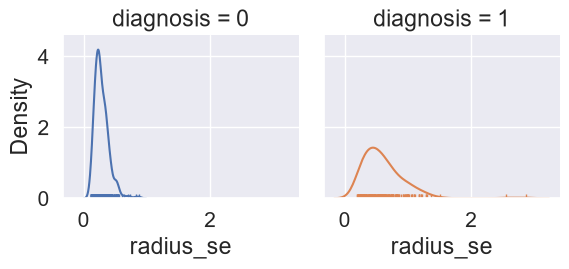

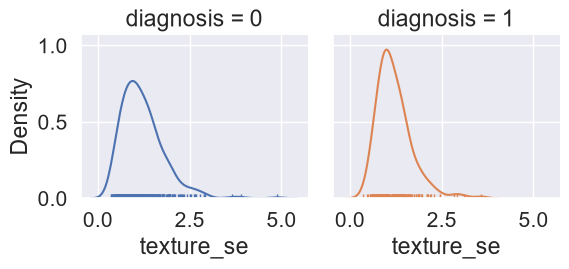

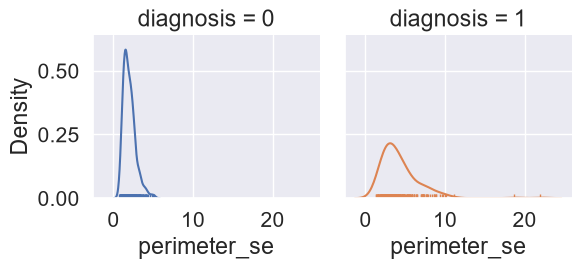

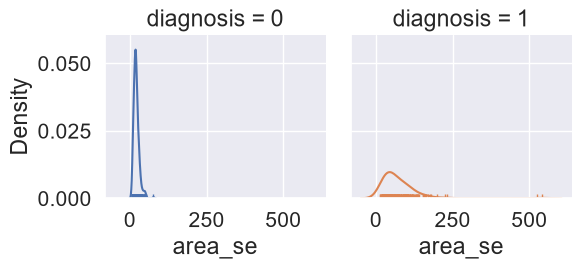

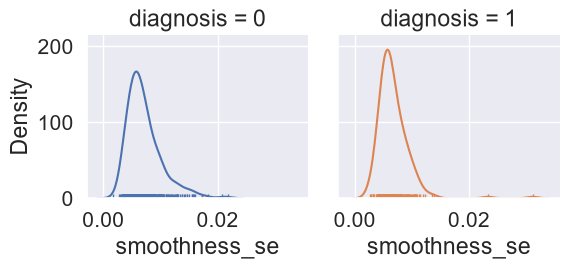

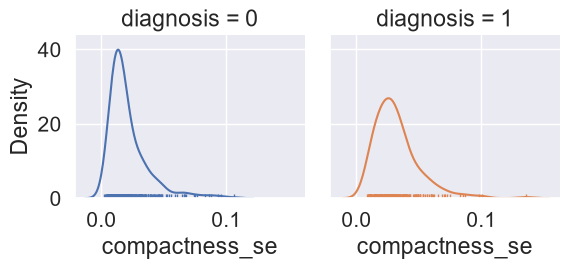

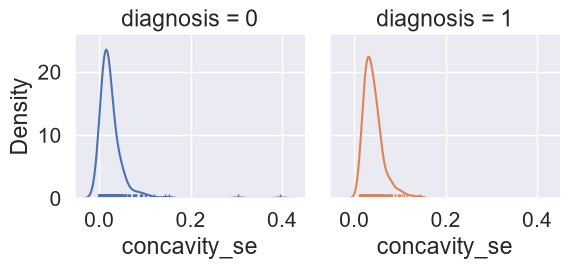

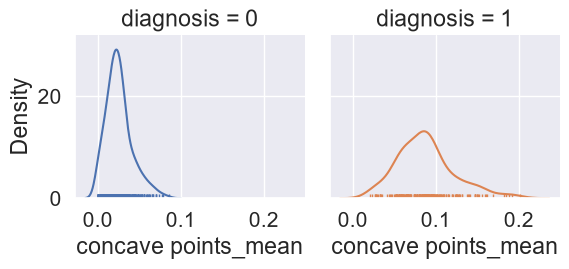

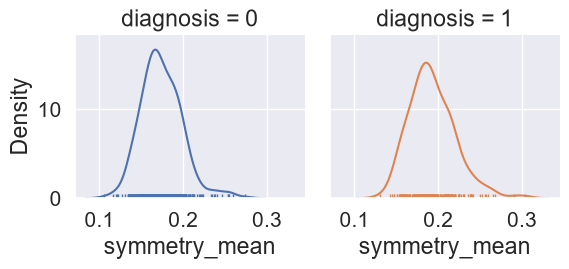

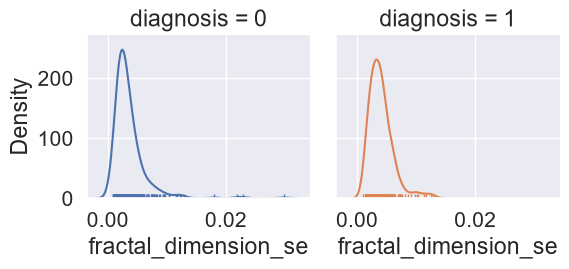

In [27]:
g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'radius_se', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'texture_se', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'perimeter_se', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "area_se", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "smoothness_se", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "compactness_se", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "concavity_se", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "concave points_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "symmetry_mean", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "fractal_dimension_se", hist = False, rug = True)
plt.show()

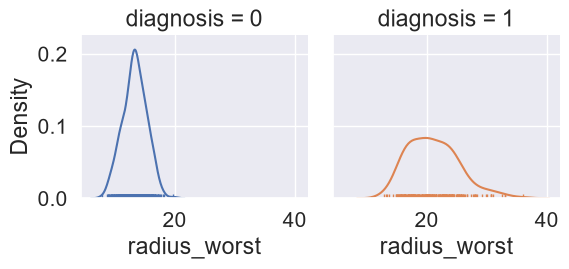

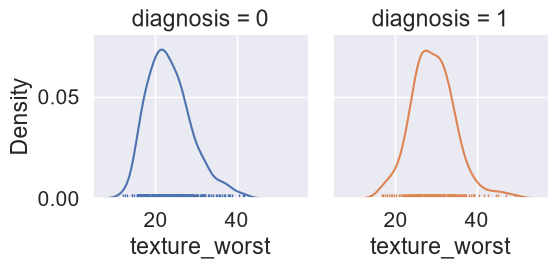

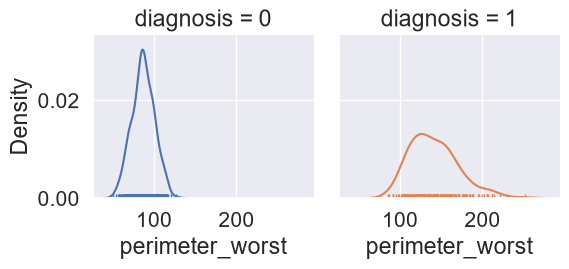

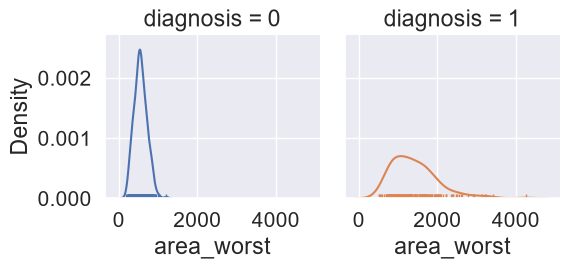

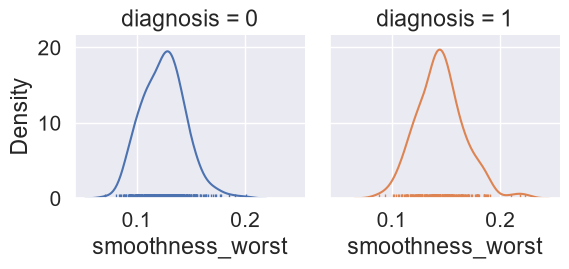

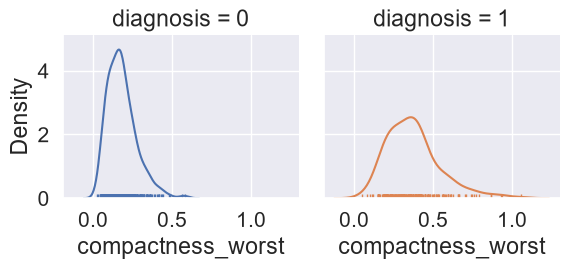

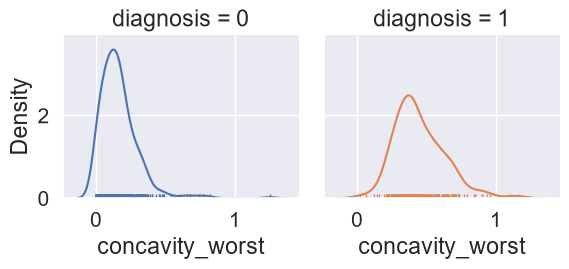

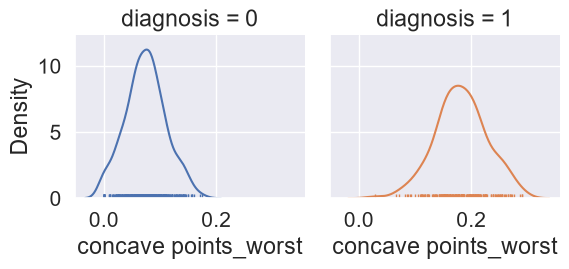

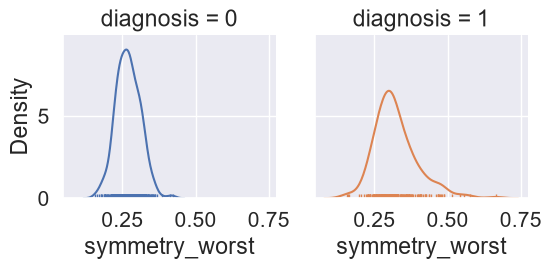

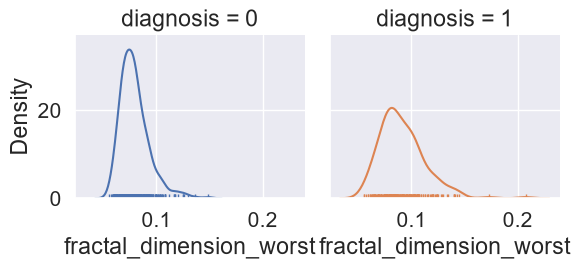

In [28]:
g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'radius_worst', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'texture_worst', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, 'perimeter_worst', hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "area_worst", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "smoothness_worst", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "compactness_worst", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "concavity_worst", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "concave points_worst", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "symmetry_worst", hist = False, rug = True)

g = s.FacetGrid (cp,col = 'diagnosis', hue = 'diagnosis')
g.map (s.distplot, "fractal_dimension_worst", hist = False, rug = True)
plt.show()

## Modelling — train, tune and save all three models


In [29]:
np.random.seed(10)
x_train,x_test, y_train,y_test = train_test_split (x,y,test_size = 0.2)
forest = RandomForestClassifier (n_estimators = 2000)
fit = forest.fit (x_train, y_train)
accuracy = fit.score(x_test,y_test)
predict = fit.predict(x_test)
cmatrix = confusion_matrix (y_test, predict)
print ('Classification Report:',classification_report(y_test,predict))
print ('Accuracy Score', (accuracy_score(y_test,predict)))
print ('Accuracy of Random Forest ', (accuracy))
print ('Confusion Matrix :\n',cmatrix)

Classification Report:               precision    recall  f1-score   support

           0       1.00      0.97      0.99        75
           1       0.95      1.00      0.97        39

    accuracy                           0.98       114
   macro avg       0.98      0.99      0.98       114
weighted avg       0.98      0.98      0.98       114

Accuracy Score 0.9824561403508771
Accuracy of Random Forest  0.9824561403508771
Confusion Matrix :
 [[73  2]
 [ 0 39]]


## Preprocessing — scale the features

SVC (and XGBoost) need features on a comparable scale, so fit a `StandardScaler` on the **training set only** and apply it to both sets. Random Forest does not need scaling (trees split on thresholds), so the baseline above stays on the unscaled data.

In [30]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
print('Scaled train shape:', x_train_scaled.shape)


Scaled train shape: (455, 30)


## Cross-validation — how stable is the Random Forest?

`cross_val_score` with 5 folds re-trains the model on 5 different train/validation splits, so the mean is a more honest estimate than a single train/test split.

In [31]:
cv_scores = cross_val_score(forest, x_train, y_train, cv=5)
print('Random Forest 5-fold CV scores:', np.round(cv_scores, 4))
print('Mean CV accuracy:', round(cv_scores.mean(), 4))


Random Forest 5-fold CV scores: [0.978  0.978  0.9451 0.967  0.9231]
Mean CV accuracy: 0.9582


## Tuning — GridSearchCV for all three models

Each `GridSearchCV` tries every combination in its grid with 5-fold CV on the training set and keeps the best. Random Forest keeps its verified 2,000 trees and tunes depth instead; SVC and XGBoost run on the scaled data.

In [32]:
rf_param_grid = {'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}
grid_rf = GridSearchCV(RandomForestClassifier(n_estimators=2000), rf_param_grid, cv=5)
grid_rf.fit(x_train, y_train)
print('Best Random Forest params:', grid_rf.best_params_)
print('Best CV accuracy:', round(grid_rf.best_score_, 4))
print('Test accuracy:', round(accuracy_score(y_test, grid_rf.predict(x_test)), 4))


Best Random Forest params: {'max_depth': None, 'min_samples_split': 2}
Best CV accuracy: 0.9582
Test accuracy: 0.9825


In [33]:
svc_param_grid = {'C': [0.1, 1, 10], 'gamma': [0.001, 0.0001, 0.01, 'scale']}
grid_svc = GridSearchCV(SVC(), svc_param_grid, cv=5)
grid_svc.fit(x_train_scaled, y_train)
print('Best SVC params:', grid_svc.best_params_)
print('Best CV accuracy:', round(grid_svc.best_score_, 4))
svc_pred = grid_svc.predict(x_test_scaled)
print('Test accuracy:', round(accuracy_score(y_test, svc_pred), 4))
print(classification_report(y_test, svc_pred))


Best SVC params: {'C': 10, 'gamma': 0.01}
Best CV accuracy: 0.9802
Test accuracy: 0.9649
              precision    recall  f1-score   support

           0       0.99      0.96      0.97        75
           1       0.93      0.97      0.95        39

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



In [34]:
xgb_param_grid = {'n_estimators': [50, 100, 200]}
grid_xgb = GridSearchCV(XGBClassifier(), xgb_param_grid, cv=5)
grid_xgb.fit(x_train_scaled, y_train)
print('Best XGBoost params:', grid_xgb.best_params_)
print('Best CV accuracy:', round(grid_xgb.best_score_, 4))
print('Test accuracy:', round(accuracy_score(y_test, grid_xgb.predict(x_test_scaled)), 4))


Best XGBoost params: {'n_estimators': 200}
Best CV accuracy: 0.9604
Test accuracy: 0.9649


## Save the tuned models

The whole `GridSearchCV` object is saved, so the best parameters and CV score travel with the model. Load with `joblib.load('models/SVC.pkl')` and call `.predict()` on it directly.

In [35]:
os.makedirs('models', exist_ok=True)
joblib.dump(grid_rf, 'models/Random Forest.pkl')
joblib.dump(grid_svc, 'models/SVC.pkl')
joblib.dump(grid_xgb, 'models/XGBoost.pkl')
print('Saved: models/Random Forest.pkl, models/SVC.pkl, models/XGBoost.pkl')


Saved: models/Random Forest.pkl, models/SVC.pkl, models/XGBoost.pkl


In [36]:
prediction = forest.predict(x)
accuracy = accuracy_score(y,prediction)
print("Accuracy of complete data:",accuracy)

Accuracy of complete data: 0.9964850615114236


### Note on the last cell — read this before quoting 99.6%

The final cell scores the model on the **full dataset, including the data it trained on**, so 99.6% is not a real result — it is expected to be high. The honest number is the **held-out test accuracy of 98.2%** (114 samples) from the cell above. Do not quote 99.6% on a resume or in an interview.